# Notebook 6 - Evaluasi Baseline dan Analisis Model

**Tahap diagram:** Analisis Hasil -> Evaluasi.

Notebook ini melaporkan metrik baseline, confusion matrix, feature importance, dan SHAP. Pemilihan baseline menggunakan validation dengan AP sebagai metrik utama; hasil test mengestimasi performa baseline dan tidak dipakai memilih kandidat eksperimen. Untuk hasil final semua kandidat, gunakan Notebook 08.


---
## 0. Setup

In [1]:
import sys
import pickle
import warnings
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import matplotlib.patches as mpatches
import seaborn as sns

warnings.filterwarnings('ignore')

ROOT = Path('..').resolve()
sys.path.insert(0, str(ROOT))

OUT       = ROOT / 'outputs' / 'results'
MODEL_DIR = ROOT / 'outputs' / 'models'
OUT.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({
    'figure.dpi': 120,
    'axes.grid': True,
    'grid.alpha': 0.3,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'font.size': 11,
})
MODEL_COLORS = ['#4472C4', '#ED7D31', '#70AD47']
print('Setup selesai.')


Setup selesai.


---
## 1. Load Model & Dataset

In [2]:
from src.preprocessing import load_splits

df_train, df_val, df_test, feature_cols, le = load_splits(ROOT / 'data' / 'processed')

X_test  = df_test[feature_cols].values.astype(np.float32)
y_test  = df_test['label'].values
X_val   = df_val[feature_cols].values.astype(np.float32)
y_val   = df_val['label'].values
X_train = df_train[feature_cols].values.astype(np.float32)
y_train = df_train['label'].values

class_names = [str(c) for c in le.classes_]
n_classes   = len(class_names)

print(f'Test set  : {X_test.shape}  (matches_par_contract=1 rate: {y_test.mean():.1%})')
print(f'Kelas     : {n_classes}  -> {class_names}')
print(f'Fitur     : {len(feature_cols)}')

trained_models = []
model_names    = ['RandomForest', 'XGBoost', 'LightGBM']
for name in model_names:
    path = MODEL_DIR / f'{name.lower()}.pkl'
    assert path.exists(), f'Model tidak ditemukan: {path}. Jalankan 05_modeling.ipynb (folder ini) terlebih dahulu.'
    with open(path, 'rb') as f:
        trained_models.append(pickle.load(f))
    print(f'  Loaded: {name}')


Test set  : (7532, 174)  (matches_par_contract=1 rate: 24.5%)
Kelas     : 2  -> ['0', '1']
Fitur     : 174


  Loaded: RandomForest
  Loaded: XGBoost
  Loaded: LightGBM


---
## 2. Evaluasi Final – Test Set

In [3]:
from src.evaluation import evaluate, print_summary, compare_models, save_results

test_results = []
predictions  = {}
probabilities = {}

for model in trained_models:
    y_pred  = model.predict(X_test)
    y_proba = model.predict_proba(X_test)
    res = evaluate(y_test, y_pred, y_proba, le, model_name=model.name)
    test_results.append(res)
    predictions[model.name]   = y_pred
    probabilities[model.name] = y_proba
    save_results(res, OUT / f'nb06_{model.name.lower()}_test.json')
    print_summary(res)



  RandomForest
  Accuracy          : 0.8032
  Precision (macro) : 0.7367
  Recall (macro)    : 0.6939
  F1 (macro)        : 0.7095
  F1 (weighted)     : 0.7935
  F1 (positive)     : 0.5446
  ROC-AUC           : 0.7812
  PR-AUC (avg prec) : 0.5888

  XGBoost
  Accuracy          : 0.8089
  Precision (macro) : 0.7596
  Recall (macro)    : 0.6716
  F1 (macro)        : 0.6947
  F1 (weighted)     : 0.7898
  F1 (positive)     : 0.5080
  ROC-AUC           : 0.7921
  PR-AUC (avg prec) : 0.5946



  LightGBM
  Accuracy          : 0.7916
  Precision (macro) : 0.7220
  Recall (macro)    : 0.7393
  F1 (macro)        : 0.7295
  F1 (weighted)     : 0.7954
  F1 (positive)     : 0.5999
  ROC-AUC           : 0.8153
  PR-AUC (avg prec) : 0.6285


In [4]:
def report_to_df(report_dict):
    """Convert sklearn classification_report output to a display DataFrame."""
    rows = {k: v for k, v in report_dict.items() if isinstance(v, dict)}
    df = pd.DataFrame(rows).T
    df['support'] = df['support'].astype(int)
    return df.rename(index={'0': 'Tidak cocok par (0)', '1': 'Cocok par (1)'})

print('=== Classification Report per Model ? Test Set ===')
for res in test_results:
    print(f'\n{res["model"]}:')
    display(report_to_df(res['per_class_report']).round(4))


=== Classification Report per Model ? Test Set ===

RandomForest:


,precision,recall,f1-score,support
Tidak cocok par (0),0.8428,0.9087,0.8745,5683
Cocok par (1),0.6306,0.4792,0.5446,1849
macro avg,0.7367,0.6939,0.7095,7532
weighted avg,0.7907,0.8032,0.7935,7532



XGBoost:


,precision,recall,f1-score,support
Tidak cocok par (0),0.8287,0.9414,0.8815,5683
Cocok par (1),0.6905,0.4018,0.5080,1849
macro avg,0.7596,0.6716,0.6947,7532
weighted avg,0.7948,0.8089,0.7898,7532



LightGBM:


,precision,recall,f1-score,support
Tidak cocok par (0),0.8769,0.8420,0.8591,5683
Cocok par (1),0.5672,0.6366,0.5999,1849
macro avg,0.7220,0.7393,0.7295,7532
weighted avg,0.8008,0.7916,0.7954,7532


In [5]:
test_df = compare_models(test_results)
test_df.to_csv(OUT / 'test_comparison.csv')

print(f'=== Tabel Perbandingan ({len(feature_cols)} fitur, target matches_par_contract) - Test Set ===')
display(test_df.style
    .format('{:.4f}')
    .highlight_max(color='#C8E6C9', axis=0)
    .highlight_min(color='#FFCDD2', axis=0)
    .set_caption('Nilai test tertinggi/terendah per metrik (deskriptif)'))


=== Tabel Perbandingan (174 fitur, target matches_par_contract) - Test Set ===


,accuracy,precision_macro,recall_macro,f1_macro,f1_weighted,f1_positive,roc_auc,average_precision
model,,,,,,,,
RandomForest,0.8032,0.7367,0.6939,0.7095,0.7935,0.5446,0.7812,0.5888
XGBoost,0.8089,0.7596,0.6716,0.6947,0.7898,0.5080,0.7921,0.5946
LightGBM,0.7916,0.7220,0.7393,0.7295,0.7954,0.5999,0.8153,0.6285


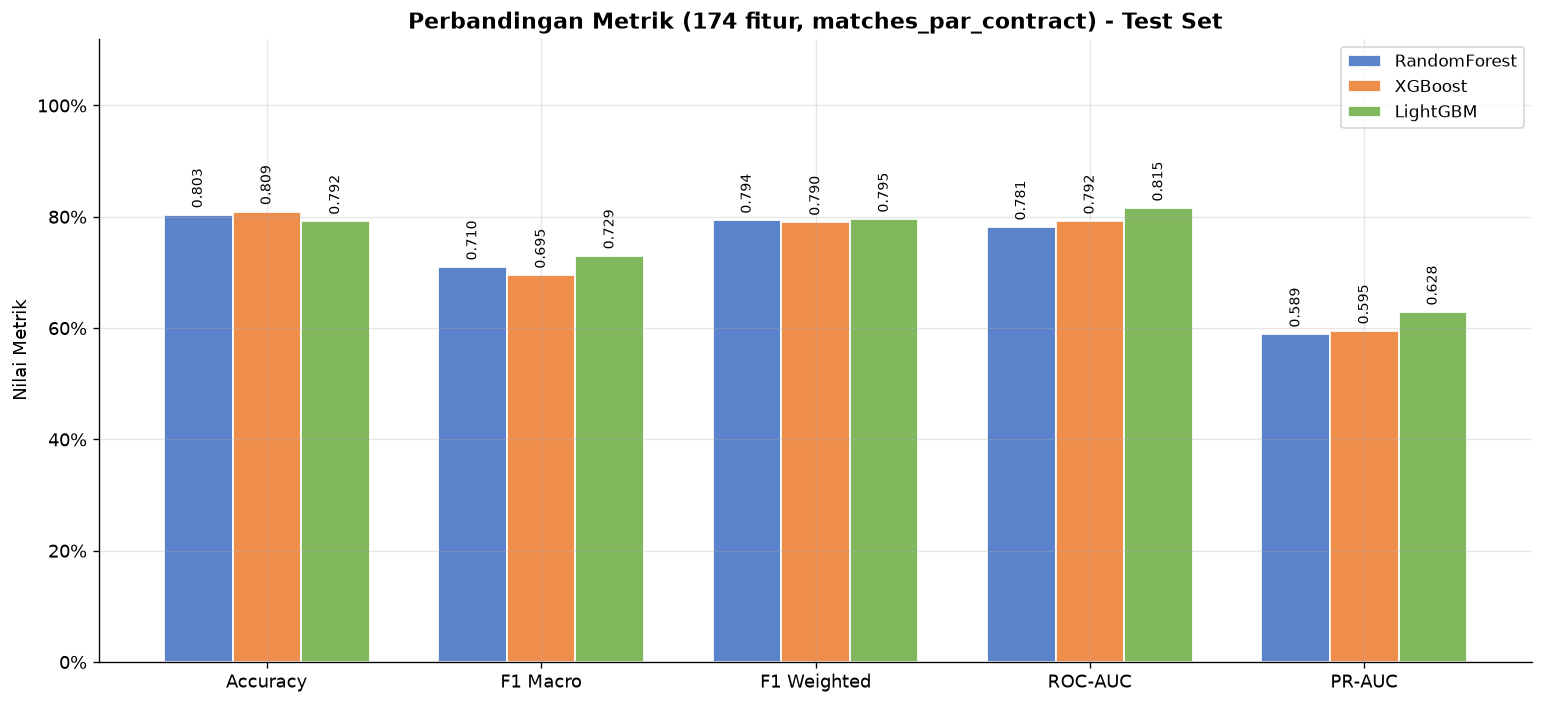

In [6]:
metrics_plot  = ['accuracy', 'f1_macro', 'f1_weighted', 'roc_auc', 'average_precision']
metrics_label = ['Accuracy', 'F1 Macro', 'F1 Weighted', 'ROC-AUC', 'PR-AUC']

x = np.arange(len(metrics_plot))
w = 0.25

fig, ax = plt.subplots(figsize=(13, 6))
for i, (res, color) in enumerate(zip(test_results, MODEL_COLORS)):
    vals = [res.get(m, 0) for m in metrics_plot]
    bars = ax.bar(x + i * w, vals, w, label=res['model'], color=color,
                  alpha=0.88, edgecolor='white', linewidth=1.2)
    ax.bar_label(bars, fmt='%.3f', fontsize=8.5, rotation=90, padding=4)

ax.set_xticks(x + w)
ax.set_xticklabels(metrics_label, fontsize=11)
ax.set_ylim(0, 1.12)
ax.set_title(f'Perbandingan Metrik ({len(feature_cols)} fitur, matches_par_contract) - Test Set', fontsize=13, fontweight='bold')
ax.set_ylabel('Nilai Metrik')
ax.yaxis.set_major_formatter(mticker.PercentFormatter(xmax=1, decimals=0))
ax.legend(fontsize=10)

plt.tight_layout()
plt.savefig(OUT / 'nb06_model_comparison.png', bbox_inches='tight')
plt.show()


---
## 3. Confusion Matrix (`matches_par_contract`)

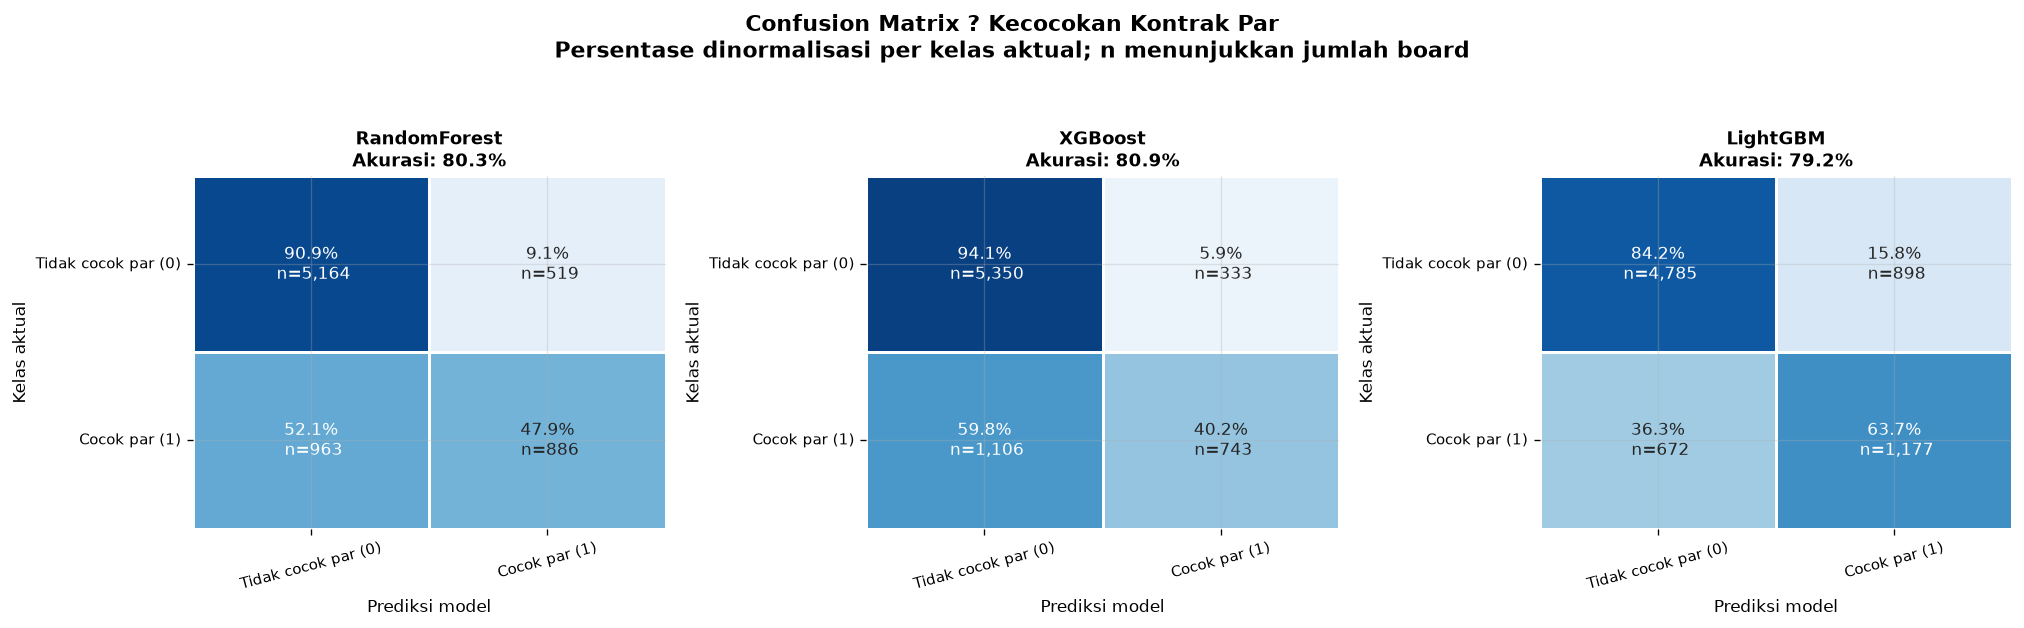

In [7]:
from sklearn.metrics import confusion_matrix

cm_labels = [0, 1]
cm_names = ['Tidak cocok par (0)', 'Cocok par (1)']
fig, axes = plt.subplots(1, len(trained_models), figsize=(17, 5))

for ax, model in zip(axes, trained_models):
    y_pred = predictions[model.name]
    mat = confusion_matrix(y_test, y_pred, labels=cm_labels)
    row_totals = mat.sum(axis=1, keepdims=True)
    mat_pct = np.divide(
        mat * 100.0, row_totals,
        out=np.zeros_like(mat, dtype=float), where=row_totals != 0,
    )
    annot = np.array([
        [f'{mat_pct[r, c]:.1f}%\n n={mat[r, c]:,}' for c in range(len(cm_labels))]
        for r in range(len(cm_labels))
    ])

    sns.heatmap(
        mat_pct, annot=annot, fmt='', cmap='Blues',
        xticklabels=cm_names, yticklabels=cm_names,
        ax=ax, cbar=False, linewidths=0.8, linecolor='white',
        vmin=0, vmax=100, annot_kws={'size': 10},
    )
    accuracy = mat.diagonal().sum() / mat.sum()
    ax.set_title(f'{model.name}\nAkurasi: {accuracy:.1%}', fontweight='bold', fontsize=11)
    ax.set_xlabel('Prediksi model', fontsize=10)
    ax.set_ylabel('Kelas aktual', fontsize=10)
    ax.tick_params(axis='x', labelsize=9, labelrotation=15)
    ax.tick_params(axis='y', labelsize=9, labelrotation=0)

fig.suptitle(
    'Confusion Matrix ? Kecocokan Kontrak Par\n'
    'Persentase dinormalisasi per kelas aktual; n menunjukkan jumlah board',
    fontsize=13, fontweight='bold', y=1.04,
)
fig.tight_layout()
fig.savefig(OUT / 'nb06_confusion_matrix_baseline.png', bbox_inches='tight', dpi=160)
plt.show()


---
## 4. Precision/Recall/F1 per Kelas (`matches_par_contract`)

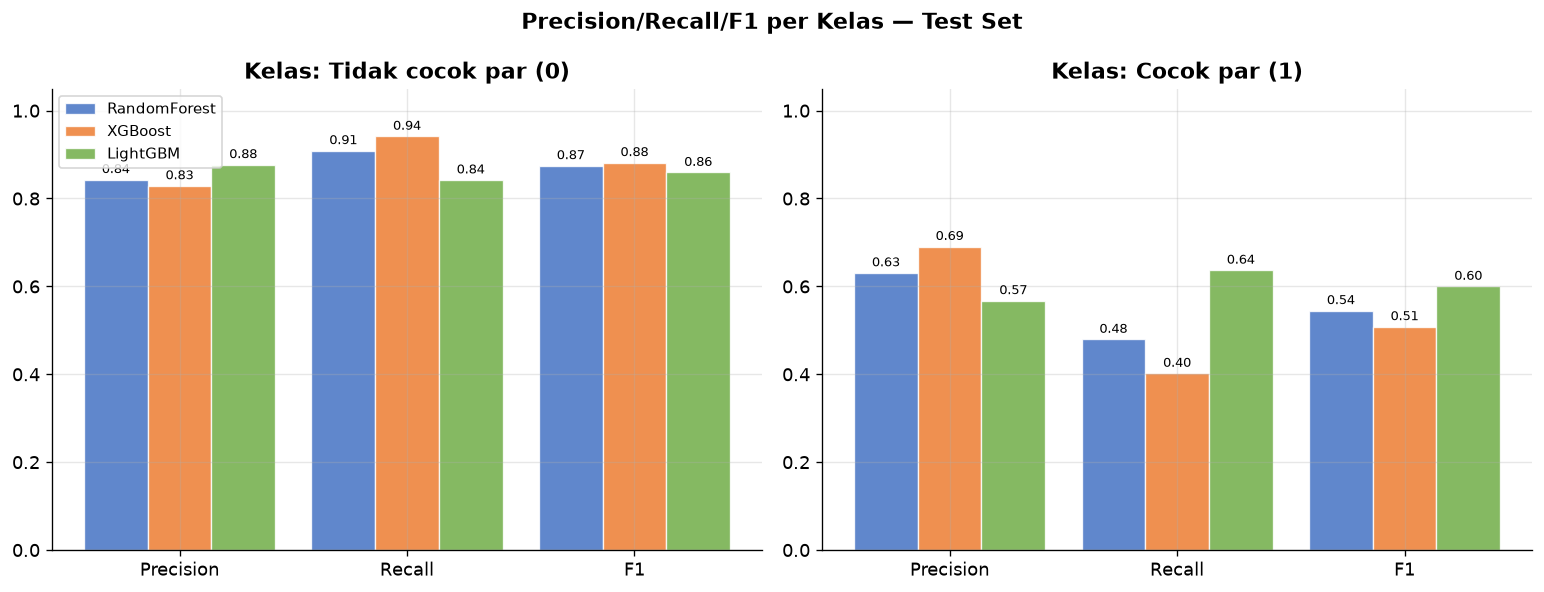

In [8]:
from sklearn.metrics import precision_recall_fscore_support

metric_labels = ['Precision', 'Recall', 'F1']
class_labels  = ['Tidak cocok par (0)', 'Cocok par (1)']

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for cls_i, (ax, cls_name) in enumerate(zip(axes, class_labels)):
    x = np.arange(len(metric_labels))
    w = 0.28
    for i, model in enumerate(trained_models):
        y_pred = predictions[model.name]
        prec, rec, f1, _ = precision_recall_fscore_support(
            y_test, y_pred, labels=[0, 1], zero_division=0
        )
        vals = [prec[cls_i], rec[cls_i], f1[cls_i]]
        bars = ax.bar(x + (i - 1) * w, vals, w, label=model.name,
                       color=MODEL_COLORS[i], alpha=0.85, edgecolor='white', linewidth=0.8)
        ax.bar_label(bars, fmt='%.2f', fontsize=8, padding=2)
    ax.set_xticks(x)
    ax.set_xticklabels(metric_labels)
    ax.set_title(f'Kelas: {cls_name}', fontweight='bold')
    ax.set_ylim(0, 1.05)
    if cls_i == 0:
        ax.legend(fontsize=9)

plt.suptitle('Precision/Recall/F1 per Kelas — Test Set', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(OUT / 'nb06_f1_per_class.png', bbox_inches='tight', dpi=150)
plt.show()


---
## 5. Feature Importance (dengan kategori DDS)

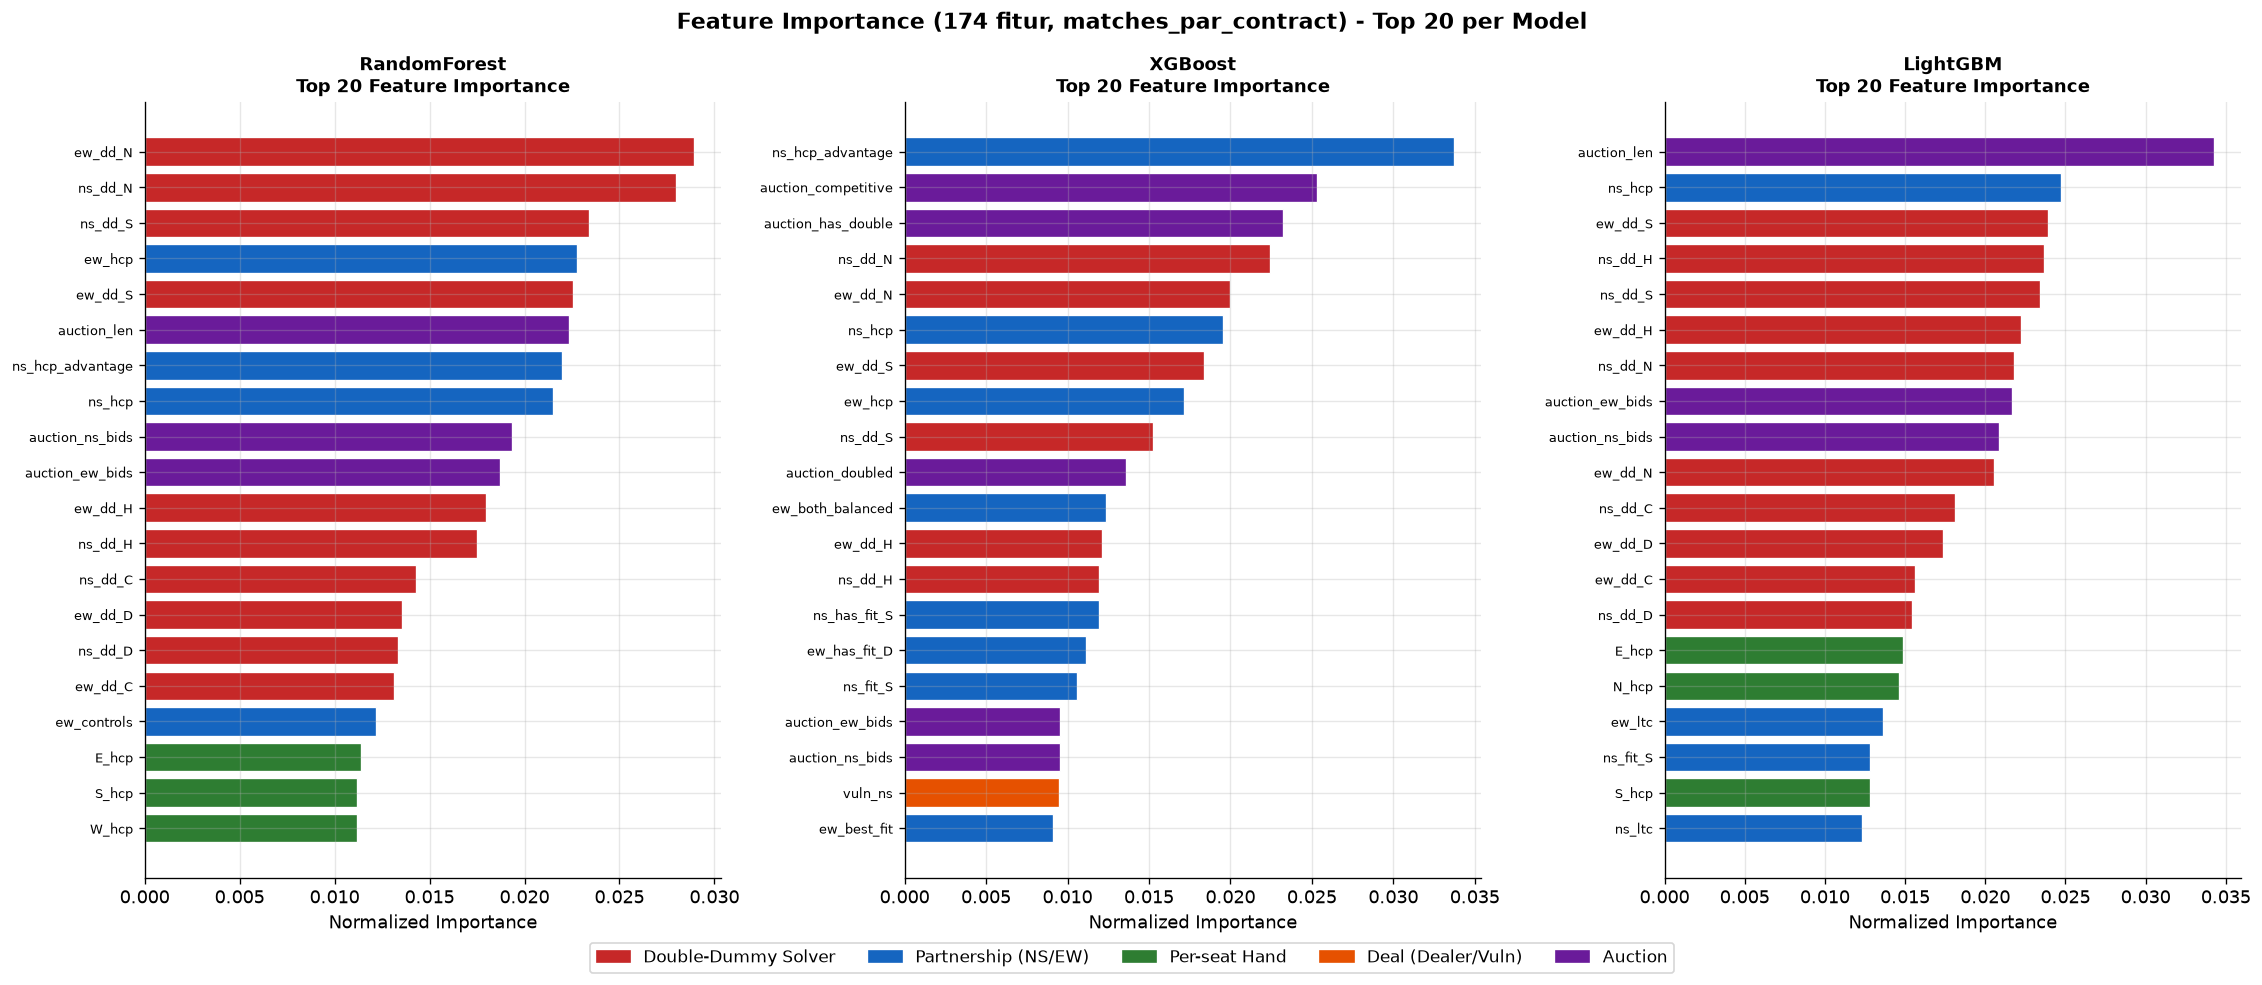

In [9]:
N_TOP = 20

def feat_group_color(name):
    if name.startswith(('ns_dd', 'ew_dd', 'dd_par')):
        return '#C62828'  # merah: Double-Dummy Solver
    if name.startswith(('ns_', 'ew_')):
        return '#1565C0'  # biru: partnership
    if len(name) >= 2 and name[0] in 'NESW' and name[1] == '_':
        return '#2E7D32'  # hijau: per-seat hand
    if name.startswith(('dealer_', 'vuln_')):
        return '#E65100'  # oranye: deal
    return '#6A1B9A'      # ungu: auction

fig, axes = plt.subplots(1, 3, figsize=(19, 8))

for ax, model, color in zip(axes, trained_models, MODEL_COLORS):
    imp = model.feature_importances()
    imp = imp / imp.sum()
    top_idx   = np.argsort(imp)[::-1][:N_TOP]
    top_names = [feature_cols[i] for i in top_idx]
    top_vals  = imp[top_idx]
    bar_colors = [feat_group_color(n) for n in top_names]

    ax.barh(
        range(N_TOP), top_vals[::-1],
        color=bar_colors[::-1], edgecolor='white', linewidth=0.8,
    )
    ax.set_yticks(range(N_TOP))
    ax.set_yticklabels(list(reversed(top_names)), fontsize=8)
    ax.set_title(f'{model.name}\nTop {N_TOP} Feature Importance', fontweight='bold', fontsize=11)
    ax.set_xlabel('Normalized Importance')

legend_el = [
    mpatches.Patch(color='#C62828', label='Double-Dummy Solver'),
    mpatches.Patch(color='#1565C0', label='Partnership (NS/EW)'),
    mpatches.Patch(color='#2E7D32', label='Per-seat Hand'),
    mpatches.Patch(color='#E65100', label='Deal (Dealer/Vuln)'),
    mpatches.Patch(color='#6A1B9A', label='Auction'),
]
fig.legend(handles=legend_el, loc='lower center', ncol=5, fontsize=10,
           bbox_to_anchor=(0.5, -0.03))

plt.suptitle(f'Feature Importance ({len(feature_cols)} fitur, matches_par_contract) - Top {N_TOP} per Model', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(OUT / 'nb06_feature_importance.png', bbox_inches='tight', dpi=150)
plt.show()


In [10]:
# Berapa banyak fitur DDS yang masuk top-20 tiap model?
for model in trained_models:
    imp = model.feature_importances()
    imp = imp / imp.sum()
    top_idx = np.argsort(imp)[::-1][:N_TOP]
    top_names = [feature_cols[i] for i in top_idx]
    n_dds = sum(1 for n in top_names if n.startswith(('ns_dd', 'ew_dd', 'dd_par')))
    print(f'{model.name:<15}: {n_dds}/{N_TOP} fitur top-20 adalah fitur DDS')

# Fitur yang konsisten penting di semua model (consensus)
all_top20 = {}
for model in trained_models:
    imp = model.feature_importances()
    imp = imp / imp.sum()
    top_idx = set(np.argsort(imp)[::-1][:20])
    all_top20[model.name] = top_idx

consensus = all_top20['RandomForest'] & all_top20['XGBoost'] & all_top20['LightGBM']
print(f'\nFitur yang masuk top-20 di SEMUA model ({len(consensus)} fitur):')
print()
avg_imp = {}
for idx in consensus:
    vals = [model.feature_importances()[idx] / model.feature_importances().sum()
            for model in trained_models]
    avg_imp[idx] = np.mean(vals)

for rank, (idx, avg) in enumerate(sorted(avg_imp.items(), key=lambda x: -x[1]), 1):
    name = feature_cols[idx]
    group = ('Double-Dummy Solver' if name.startswith(('ns_dd','ew_dd','dd_par')) else
             'Partnership' if name.startswith(('ns_','ew_')) else
             'Per-seat Hand' if (name[0] in 'NESW' and '_' in name) else
             'Deal' if name.startswith(('dealer_','vuln_')) else 'Auction')
    print(f'  {rank:2d}. {name:<35}  avg={avg:.4f}  [{group}]')


RandomForest   : 10/20 fitur top-20 adalah fitur DDS
XGBoost        : 6/20 fitur top-20 adalah fitur DDS
LightGBM       : 10/20 fitur top-20 adalah fitur DDS

Fitur yang masuk top-20 di SEMUA model (9 fitur):



   1. ns_dd_N                              avg=0.0241  [Double-Dummy Solver]
   2. ew_dd_N                              avg=0.0231  [Double-Dummy Solver]
   3. ns_hcp                               avg=0.0219  [Partnership]
   4. ew_dd_S                              avg=0.0216  [Double-Dummy Solver]
   5. ns_dd_S                              avg=0.0207  [Double-Dummy Solver]
   6. ns_dd_H                              avg=0.0177  [Double-Dummy Solver]
   7. ew_dd_H                              avg=0.0174  [Double-Dummy Solver]
   8. auction_ew_bids                      avg=0.0166  [Auction]
   9. auction_ns_bids                      avg=0.0166  [Auction]


---
## 6. SHAP Analysis

In [11]:
try:
    import shap
    SHAP_OK = True
    print(f'SHAP {shap.__version__} tersedia.')
except ImportError:
    SHAP_OK = False
    print('SHAP tidak tersedia. Install: pip install shap')
    print('Melewati seksi SHAP.')


SHAP 0.52.0 tersedia.


In [12]:
if SHAP_OK:
    xgb_model = next(m for m in trained_models if m.name == 'XGBoost')
    X_shap    = X_test[:300]

    print('Menghitung SHAP values untuk XGBoost (300 sampel)...')
    explainer   = shap.TreeExplainer(xgb_model.clf)
    shap_values = explainer.shap_values(X_shap)

    # Untuk binary classification, TreeExplainer bisa mengembalikan array 2D
    # (n_samples, n_features) langsung, ATAU (tergantung versi shap/xgboost)
    # list/array 3D per kelas -- ambil kelas positif (matches_par_contract=1) di kasus itu.
    sv = np.array(shap_values)
    if sv.ndim == 3:
        sv = sv[:, :, 1]
    elif isinstance(shap_values, list):
        sv = np.array(shap_values[1])
    print(f'Selesai. Shape SHAP (kelas positif "Cocok par"): {sv.shape}')


Menghitung SHAP values untuk XGBoost (300 sampel)...


Selesai. Shape SHAP (kelas positif "Cocok par"): (300, 174)


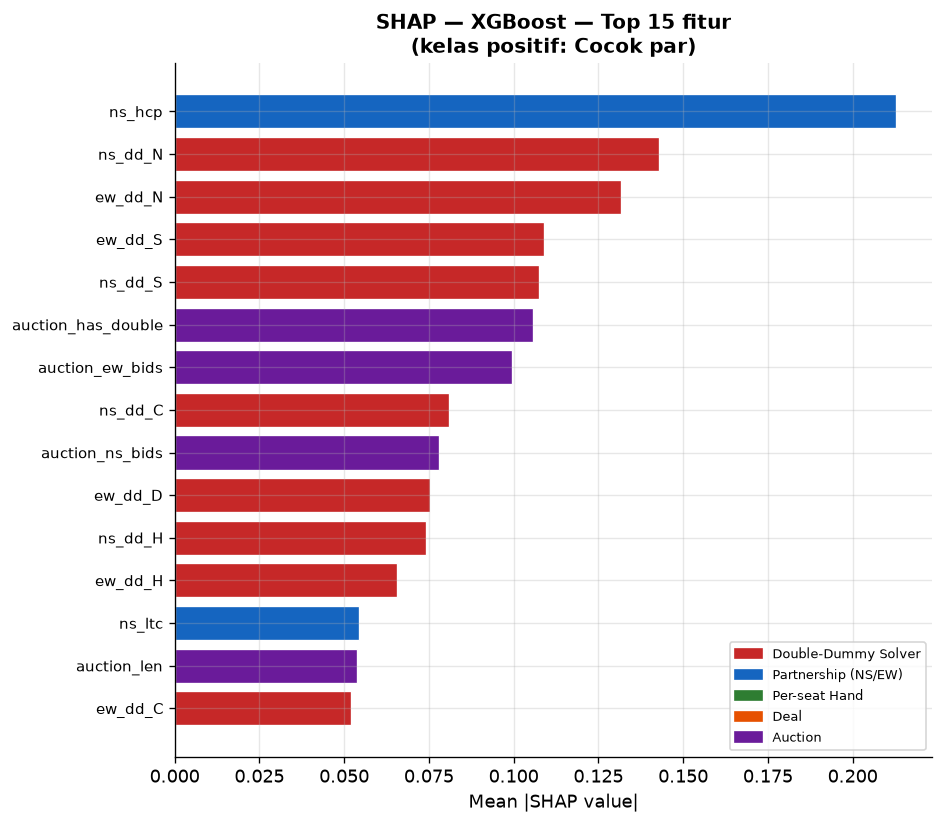

In [13]:
if SHAP_OK:
    mean_abs = np.abs(sv).mean(axis=0)
    top15    = np.argsort(mean_abs)[::-1][:15]
    names15  = [feature_cols[i] for i in top15]
    vals15   = mean_abs[top15]
    bar_cols = [feat_group_color(n) for n in names15]

    fig, ax = plt.subplots(figsize=(8, 7))
    ax.barh(range(15), vals15[::-1], color=bar_cols[::-1],
            edgecolor='white', linewidth=0.8)
    ax.set_yticks(range(15))
    ax.set_yticklabels(list(reversed(names15)), fontsize=9)
    ax.set_title('SHAP — XGBoost — Top 15 fitur\n(kelas positif: Cocok par)', fontweight='bold', fontsize=12)
    ax.set_xlabel('Mean |SHAP value|')

    legend_el = [
        mpatches.Patch(color='#C62828', label='Double-Dummy Solver'),
        mpatches.Patch(color='#1565C0', label='Partnership (NS/EW)'),
        mpatches.Patch(color='#2E7D32', label='Per-seat Hand'),
        mpatches.Patch(color='#E65100', label='Deal'),
        mpatches.Patch(color='#6A1B9A', label='Auction'),
    ]
    ax.legend(handles=legend_el, loc='lower right', fontsize=8)

    plt.tight_layout()
    plt.savefig(OUT / 'nb06_shap_analysis.png', bbox_inches='tight', dpi=150)
    plt.show()


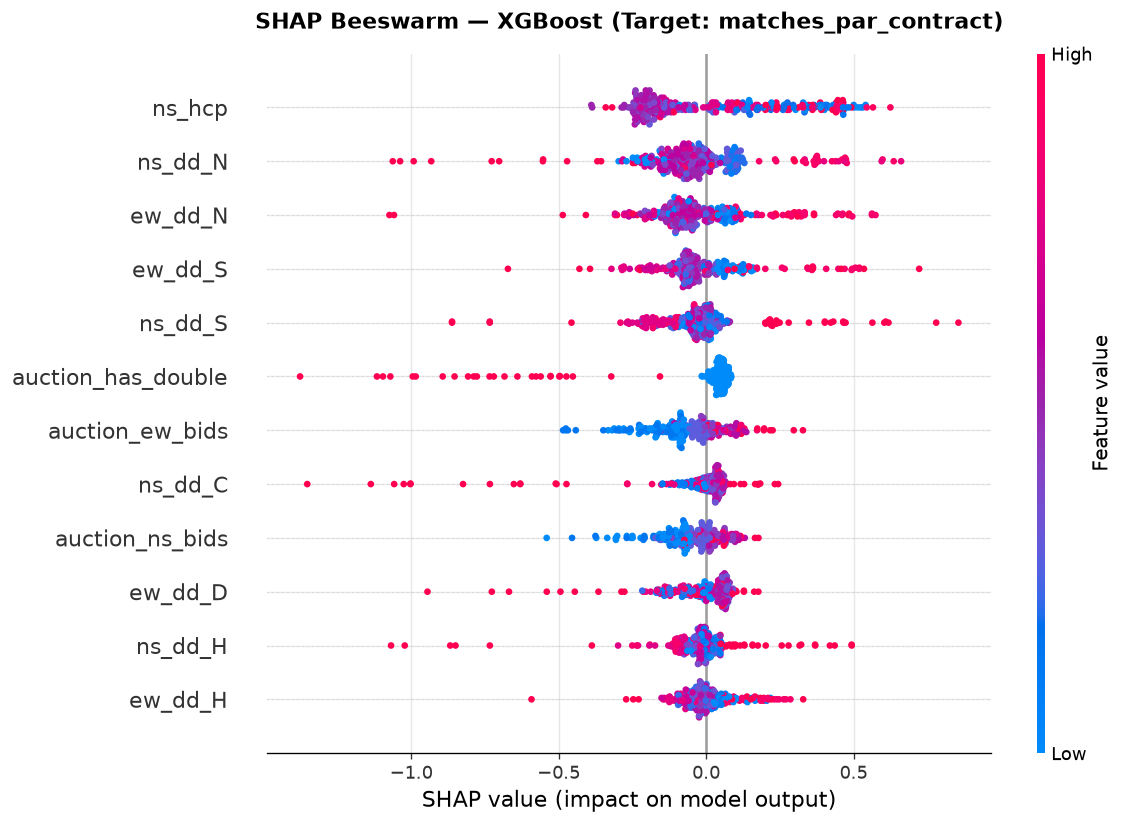

In [14]:
if SHAP_OK:
    top12 = np.argsort(mean_abs)[::-1][:12]

    fig, ax = plt.subplots(figsize=(10, 7))
    shap.summary_plot(
        sv[:, top12],
        X_shap[:, top12],
        feature_names=[feature_cols[i] for i in top12],
        show=False, plot_size=None,
    )
    plt.title('SHAP Beeswarm — XGBoost (Target: matches_par_contract)',
              fontweight='bold', pad=15)
    plt.tight_layout()
    plt.savefig(OUT / 'nb06_shap_beeswarm.png', bbox_inches='tight', dpi=150)
    plt.show()


---
## 7. Radar Chart & Kesimpulan Akhir

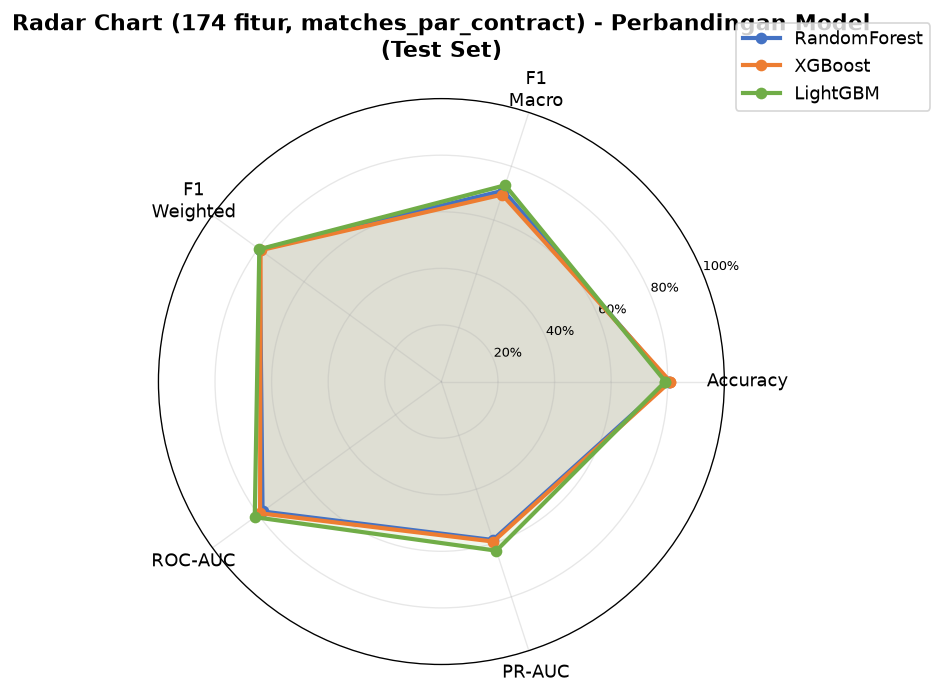

In [15]:
metrics_radar = ['accuracy', 'f1_macro', 'f1_weighted', 'roc_auc', 'average_precision']
labels_radar  = ['Accuracy', 'F1\nMacro', 'F1\nWeighted', 'ROC-AUC', 'PR-AUC']
N = len(metrics_radar)
angles = np.linspace(0, 2 * np.pi, N, endpoint=False).tolist() + [0]

fig, ax = plt.subplots(figsize=(7, 7), subplot_kw={'polar': True})

for res, color in zip(test_results, MODEL_COLORS):
    vals = [res.get(m, 0) for m in metrics_radar] + [res.get(metrics_radar[0], 0)]
    ax.plot(angles, vals, 'o-', lw=2.5, label=res['model'], color=color)
    ax.fill(angles, vals, alpha=0.10, color=color)

ax.set_xticks(angles[:-1])
ax.set_xticklabels(labels_radar, fontsize=11)
ax.set_ylim(0, 1)
ax.set_yticks([0.2, 0.4, 0.6, 0.8, 1.0])
ax.set_yticklabels(['20%', '40%', '60%', '80%', '100%'], fontsize=8)
ax.set_title(f'Radar Chart ({len(feature_cols)} fitur, matches_par_contract) - Perbandingan Model\n(Test Set)', fontweight='bold', pad=25)
ax.legend(loc='upper right', bbox_to_anchor=(1.38, 1.15), fontsize=11)

plt.tight_layout()
plt.savefig(OUT / 'nb06_radar.png', bbox_inches='tight', dpi=150)
plt.show()


In [16]:
# Test metrics are descriptive; validation scores determine the baseline choice.
import json

n_total = len(df_train) + len(df_val) + len(df_test)
n_classes = len(le.classes_)
n_features = len(feature_cols)
val_results = []
for model in trained_models:
    val_results.append(evaluate(
        y_val, model.predict(X_val), model.predict_proba(X_val), le, model_name=model.name
    ))
val_best_ap = max(val_results, key=lambda r: r['average_precision'])
val_best_f1 = max(val_results, key=lambda r: r['f1_macro'])
val_best_accuracy = max(val_results, key=lambda r: r['accuracy'])

print('=' * 66)
print(f'  EVALUASI ({n_features} fitur, target matches_par_contract)')
print('=' * 66)
print(f'\nDataset: {n_total:,} board; split {len(df_train):,}/{len(df_val):,}/{len(df_test):,}')
print(f'Fitur: {n_features}; prevalensi positif test: {y_test.mean():.2%}')
print('\nSkor test baseline (deskriptif):')
print(f'  {"Model":<15} {"Accuracy":>10} {"F1 Macro":>10} {"F1 Positif":>12} {"ROC-AUC":>9} {"AP":>8}')
for res in test_results:
    print(f'  {res["model"]:<15} {res["accuracy"]:>10.4f} {res["f1_macro"]:>10.4f} '
          f'{res["f1_positive"]:>12.4f} {res.get("roc_auc", 0):>9.4f} '
          f'{res.get("average_precision", 0):>8.4f}')
print(f'\nDipilih dari validation berdasarkan AP: {val_best_ap["model"]}')
print(f'  estimasi test AP={next(r["average_precision"] for r in test_results if r["model"] == val_best_ap["model"]):.4f}')
print(f'Pilihan baseline berdasarkan F1 macro (sekunder): {val_best_f1["model"]}')
print(f'  estimasi test F1 macro={next(r["f1_macro"] for r in test_results if r["model"] == val_best_f1["model"]):.4f}')
print(f'Dipilih dari validation berdasarkan accuracy: {val_best_accuracy["model"]}')
print('Peringkat test tidak digunakan untuk memilih model.')

summary = {
    'dataset': {
        'n_total': n_total, 'n_train': len(df_train), 'n_val': len(df_val),
        'n_test': len(df_test), 'n_classes': n_classes, 'n_features': n_features,
        'matches_par_contract_rate_test': float(y_test.mean()),
    },
    'primary_selection_metric': 'average_precision on validation',
    'secondary_selection_metric': 'f1_macro on validation',
    'validation_results': [
        {k: v for k, v in r.items() if k not in ('per_class_report', 'confusion_matrix', 'class_names')}
        for r in val_results
    ],
    'test_results_descriptive': [
        {k: v for k, v in r.items() if k not in ('per_class_report', 'confusion_matrix', 'class_names')}
        for r in test_results
    ],
    'selected_by_validation_average_precision': val_best_ap['model'],
    'selected_by_validation_f1_macro': val_best_f1['model'],
    'selected_by_validation_accuracy': val_best_accuracy['model'],
}
summary_path = OUT / 'nb06_summary.json'
summary_path.write_text(json.dumps(summary, indent=2), encoding='utf-8')
print(f'\nRingkasan JSON disimpan: {summary_path.name}')


  EVALUASI (174 fitur, target matches_par_contract)

Dataset: 50,227 board; split 35,161/7,534/7,532
Fitur: 174; prevalensi positif test: 24.55%

Skor test baseline (deskriptif):
  Model             Accuracy   F1 Macro   F1 Positif   ROC-AUC       AP
  RandomForest        0.8032     0.7095       0.5446    0.7812   0.5888
  XGBoost             0.8089     0.6947       0.5080    0.7921   0.5946
  LightGBM            0.7916     0.7295       0.5999    0.8153   0.6285

Dipilih dari validation berdasarkan AP: LightGBM
  estimasi test AP=0.6285
Pilihan baseline berdasarkan F1 macro (sekunder): LightGBM
  estimasi test F1 macro=0.7295
Dipilih dari validation berdasarkan accuracy: XGBoost
Peringkat test tidak digunakan untuk memilih model.

Ringkasan JSON disimpan: nb06_summary.json
